# DistClassiPy Tutorial

**Author**: Sid Chaini, October 22, 2024

This notebook gives a quick demo of using DistClassiPy to classify light curve features. For this demo, I will use the data from the Zwicky Transient Facility Source Classification Project (SCoPe, [Healy et al. 2024)](https://arxiv.org/abs/2312.00143).

<!-- [![github-badge](https://img.shields.io/badge/GitHub-sidchaini/DistClassiPyTutorial-blue)](https://github.com/sidchaini/DistClassiPyTutorial) -->
[![colab-button](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sidchaini/DistClassiPyTutorial/blob/main/tutorial.ipynb)


### 0. Prerequisites

Let us first install DistClassiPy from PyPI, if it isn't installed already. Version 0.4.0 or later is needed for the EnsembleDistanceClassifier in section 4.

In [1]:
import importlib.util

if importlib.util.find_spec("distclassipy") is None:
    %pip install "distclassipy>=0.4.0"

Let's download a dataset I prepared from the ZTF SCoPE data for this tutorial.

In [2]:
%%capture
!wget https://github.com/sidchaini/DistClassiPyTutorial/archive/refs/heads/main.zip
!unzip main.zip
!mv DistClassiPyTutorial-main/* .
!rm -rf main.zip DistClassiPyTutorial-main

In [3]:
import numpy as np

seed = 0
np.random.seed(seed)
import pandas as pd
import distclassipy as dcpy
import utils
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

### 1. Visualizing 2D distance metric spaces

We can visualize the distance metric space by plotting the locus of a central point, such as (5, 5) in a given two dimensional space. The locus appear as contour lines, which can illustrate geometry of the space when plotted in Euclidean space.

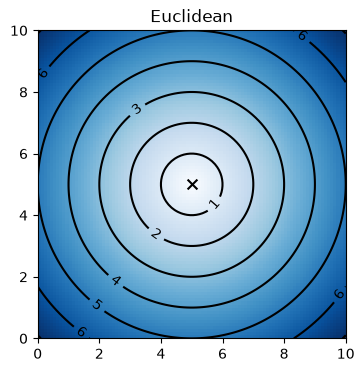

In [4]:
utils.visualize_distance("euclidean")
plt.show()

### 2. Data

For this example, we will be using data from "The ZTF Source Classification Project: III. A Catalog of Variable Sources" through which they have made available on Zenodo.

[![zenodo-badge](https://zenodo.org/badge/DOI/10.5281/zenodo.13920513.svg)](https://zenodo.org/records/13920513)

I downloaded and sampled them to choose 4000 objects from 4 classes of variable stars:

In [5]:
features = pd.read_csv("data/ztfscope_features.csv", index_col=0)
labels = pd.read_csv("data/ztfscope_labels.csv", index_col=0)

In [6]:
labels.value_counts()

class
CEP      1000
RRc      1000
DSCT     1000
RR       1000
Name: count, dtype: int64

For the sake of simplicity, let us focus on three features from the complete ZTF SCoPE features (refer to [Healy et al. 2024](https://arxiv.org/abs/2312.00143) for more details):
- ```inv_vonneumannratio```: Inverse of von Neumann ratio ([von Neumann 1941](https://projecteuclid.org/journals/annals-of-mathematical-statistics/volume-12/issue-4/Distribution-of-the-Ratio-of-the-Mean-Square-Successive-Difference/10.1214/aoms/1177731677.full), [1942](https://projecteuclid.org/journals/annals-of-mathematical-statistics/volume-13/issue-1/A-Further-Remark-Concerning-the-Distribution-of-the-Ratio-of/10.1214/aoms/1177731645.full)), which is the ratio of correlated variance and variance - it detects non-randomness, and a high value implies periodic behaviour.
- ```norm_peak_to_peak_amp```: Normalized peak-to-peak amplitude [(Sokolovsky et al. 2009)](https://arxiv.org/abs/0901.1064) - it tells us about the source brightness.
- ```stetson_k```: Stetson K coefficient ([Stetson 1996](https://iopscience.iop.org/article/10.1086/133808/meta?casa_token=EMo0hxKqIkUAAAAA:b8y8ONGzEQAJq2WJfrCASQt_FMw7HX_h7i-VChDbTYc1ShDkEih4I2Sm184VFLTS1UpDbATGN8GPmTY4YXRG87jP2Q)) is related to the observed scatter - it tells us about the light curve shape.

In [7]:
feature_names = ["inv_vonneumannratio", "norm_peak_to_peak_amp", "stetson_k"]

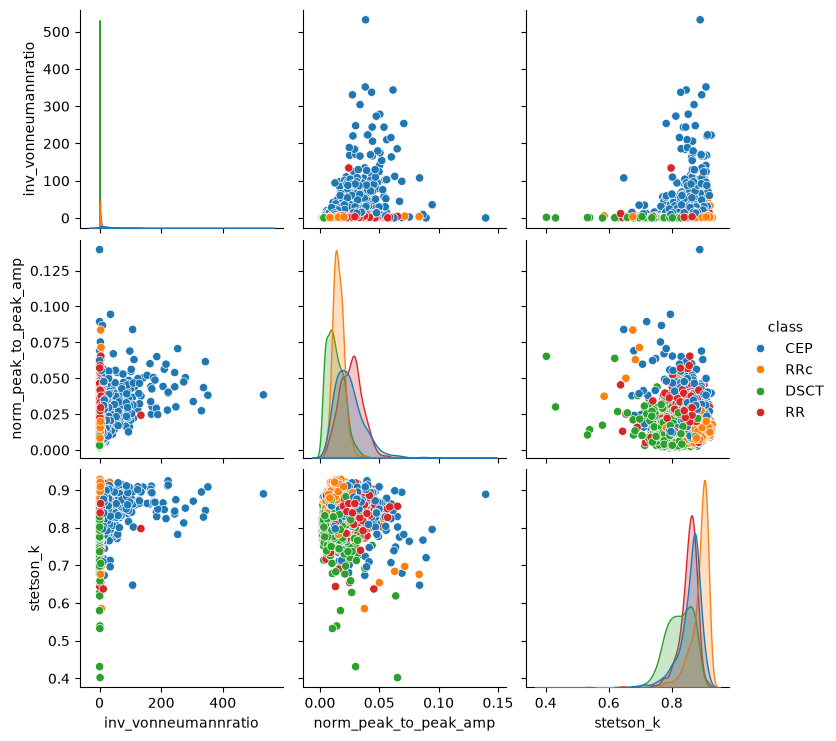

In [8]:
df = features.loc[:, feature_names]
df["class"] = labels["class"]
sns.pairplot(df, hue="class")
plt.show()

In [9]:
X = features.loc[:, feature_names].to_numpy()
y = labels.to_numpy().ravel()

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=seed
)

### 3. DistanceMetricClassifier

The DistanceMetricClassifier calculates the distance between a centroid for each class, and each test point, and scales it by the standard deviation.

In [11]:
clf = dcpy.DistanceMetricClassifier()
clf.fit(X_train, y_train)

,metric,None
,scale,True
,central_stat,'median'
,dispersion_stat,'std'
,cdf_grid_size,1001
,reference,'centroid'
,n_neighbors,5
Name,Type,Value
classes_,"ndarray[<U4](4,)","['CEP','DSCT','RR','RRc']"
df_centroid_,DataFrame,Feature...788 0.896614
df_std_,DataFrame,Feature...184 0.033750


In [12]:
y_pred = clf.predict_and_analyse(X_test, metric="euclidean")

In [13]:
acc = accuracy_score(y_true=y_test, y_pred=y_pred)
f1 = f1_score(y_true=y_test, y_pred=y_pred, average="macro")

print(f"Accuracy = {acc:.3f}")
print(f"F1 = {f1:.3f}")

Accuracy = 0.642
F1 = 0.635


In [14]:
clf.centroid_dist_df_

,CEP_dist,DSCT_dist,RR_dist,RRc_dist
0,0.805759,2.641208,0.824424,2.848626
1,1.220526,1.423540,2.151157,1.164521
2,1.325282,3.792195,1.503853,4.076885
3,1.064865,8.376741,1.781160,1.323827
4,0.480929,2.229321,0.915641,2.055988
...,...,...,...,...
995,1.015133,3.548696,1.743593,0.106400
996,0.957050,10.627296,1.705001,1.205451
997,0.810418,14.319456,1.574726,1.767178
998,1.023541,2.556731,1.699193,0.937611


### 4. EnsembleDistanceClassifier

Which metric should we use? The EnsembleDistanceClassifier lets us avoid choosing. It gives every metric its own DistanceMetricClassifier, using the features that suit that metric (selected automatically with sequential feature selection, or given with ```feature_sets```). Each metric's distances are turned into class probabilities, and the ensemble averages them, weighting each metric by its cross-validated F1 score, so better metrics count more.

In [15]:
ensemble_clf = dcpy.EnsembleDistanceClassifier()
ensemble_clf.fit(X_train, y_train)

,metrics,None
,feature_sets,None
,scale,True
,central_stat,'median'
,dispersion_stat,'std'
,reference,'knn'
,n_neighbors,15
,weights,'f1'
,cv,5
,max_features,None
,n_jobs,None


In [16]:
y_pred_ensemble = ensemble_clf.predict(X_test)

In [17]:
acc = accuracy_score(y_true=y_test, y_pred=y_pred_ensemble)
f1 = f1_score(y_true=y_test, y_pred=y_pred_ensemble, average="macro")

print(f"Accuracy = {acc:.3f}")
print(f"F1 = {f1:.3f}")

Accuracy = 0.798
F1 = 0.792


The weight of each metric, its cross-validated F1 score, and the features it uses:

In [18]:
metric_summary = pd.DataFrame(
    {
        "weight": ensemble_clf.weights_,
        "cv_f1": ensemble_clf.cv_scores_,
        "features": pd.Series(
            {m: [feature_names[i] for i in idx] for m, idx in ensemble_clf.feature_sets_.items()}
        ),
    }
)
metric_summary.sort_values("weight", ascending=False)

,weight,cv_f1,features
canberra,0.074653,0.780563,"[inv_vonneumannratio, norm_peak_to_peak_amp]"
wave_hedges,0.074620,0.780215,"[inv_vonneumannratio, norm_peak_to_peak_amp]"
clark,0.074526,0.779238,"[inv_vonneumannratio, norm_peak_to_peak_amp]"
hellinger,0.073199,0.765363,"[inv_vonneumannratio, norm_peak_to_peak_amp, s..."
kulczynski,0.068942,0.720852,"[inv_vonneumannratio, norm_peak_to_peak_amp]"
braycurtis,0.068877,0.720164,"[inv_vonneumannratio, norm_peak_to_peak_amp]"
motyka,0.068877,0.720164,"[inv_vonneumannratio, norm_peak_to_peak_amp]"
soergel,0.068838,0.719763,"[inv_vonneumannratio, norm_peak_to_peak_amp]"
jaccard,0.066206,0.692245,[inv_vonneumannratio]
euclidean,0.058156,0.608072,"[inv_vonneumannratio, norm_peak_to_peak_amp, s..."


We can also see how each metric voted for a single object, here the first test object:

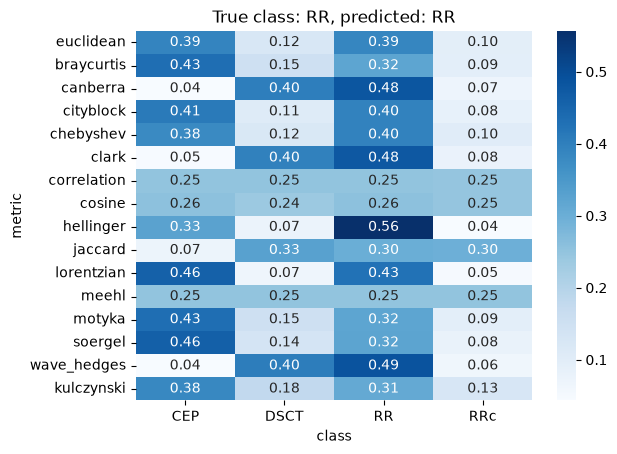

In [19]:
votes = ensemble_clf.predict_proba_per_metric(X_test[:1]).iloc[0].unstack()
sns.heatmap(votes, annot=True, fmt=".2f", cmap="Blues")
plt.title(f"True class: {y_test[0]}, predicted: {y_pred_ensemble[0]}")
plt.show()